<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model Ch 4 Figures — Colab Notebook
**The Standard Model · Chapter 4: Anomalies**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch04/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §4.1    | Triangle ($AVV$) anomaly diagram: two loop orientations and Fujikawa method |
| fig02  | §4.2    | $\pi^0\to\gamma\gamma$ decay rate vs $N_c$: anomaly prediction confirmed by experiment |
| fig03  | §4.3    | SM anomaly cancellation: hypercharge sum rules visualised per generation |

## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Arc
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
import os

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
TEAL   = '#2ec4b6'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#e8a838'

def hex_alpha(hexcol, alpha=0.14):
    """Safe RGBA fill — avoids broken col+'18' string trick."""
    r, g, b, _ = to_rgba(hexcol)
    return (r, g, b, alpha)

plt.rcParams.update({
    'figure.facecolor'   : BG,
    'axes.facecolor'     : BG,
    'text.color'         : FG,
    'axes.labelcolor'    : FG,
    'xtick.color'        : FG,
    'ytick.color'        : FG,
    'axes.edgecolor'     : EDGE,
    'grid.color'         : EDGE,
    'grid.alpha'         : 0.3,
    'font.size'          : 12,
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : TEAL,
    'legend.framealpha'  : 0.3,
    'legend.edgecolor'   : EDGE,
    'xtick.major.size'   : 4,
    'ytick.major.size'   : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'     : 1.2,
    'lines.linewidth'    : 2.2,
    'figure.dpi'         : 110,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')


Setup complete.


---
## fig01 · Triangle ($AVV$) Anomaly Diagram (§4.1)

**Left**: $AVV$ triangle diagram — axial current $A$ and two vector currents $V$ on external legs;
two fermion-loop orientations that cannot both be regulated simultaneously  
**Middle**: Fujikawa method — the path-integral measure Jacobian under axial rotation  
**Right**: Anomalous Ward identity: $\partial_\mu j_A^\mu = (e^2/16\pi^2)\,F\tilde F$

  saved -> figures/ch04/fig01_triangle_anomaly.png


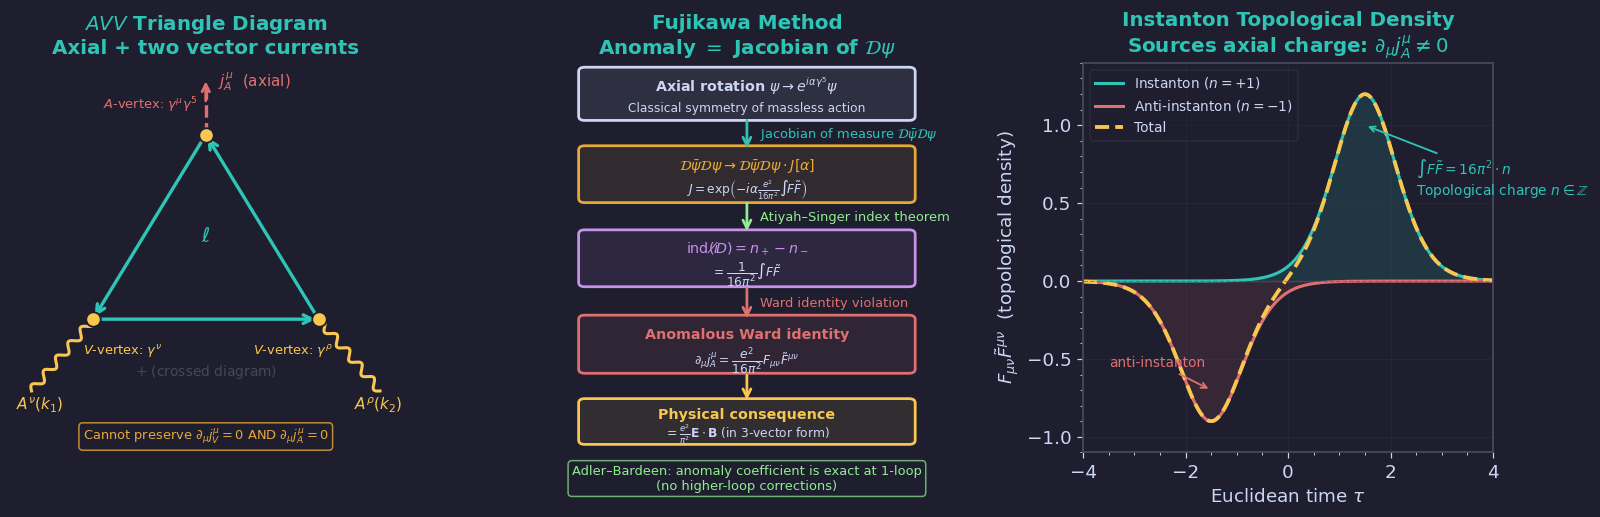

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── helpers ───────────────────────────────────────────────────────────────
def wavy_line(ax, x1, y1, x2, y2, col=YELLOW, n=6, amp=0.05, lw=2.0):
    """Wavy photon line."""
    t   = np.linspace(0, 1, 300)
    ang = np.arctan2(y2-y1, x2-x1)
    L   = np.hypot(x2-x1, y2-y1)
    s   = t * L
    p   = amp * np.sin(2*np.pi*n*t)
    xc  = x1 + s*np.cos(ang) - p*np.sin(ang)
    yc  = y1 + s*np.sin(ang) + p*np.cos(ang)
    ax.plot(xc, yc, color=col, lw=lw)

def arrow_line(ax, x1, y1, x2, y2, col, lw=2.0):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=col, lw=lw,
                                mutation_scale=14))

def vdot(ax, x, y, col=YELLOW, s=90):
    ax.scatter([x], [y], s=s, color=col, zorder=7,
               edgecolors=BG, linewidth=1.2)

# ── Left: AVV triangle diagram ────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(-0.3, 3.5)
ax.set_ylim(-0.3, 3.5)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(r'$AVV$ Triangle Diagram' + '\n'
             r'Axial + two vector currents', color=TEAL)

# Triangle vertices
Vx = [1.6, 0.5, 2.7]   # x coords
Vy = [2.8, 1.0, 1.0]   # y coords

# Fermion loop (triangle) — two orientations shown with different alphas
for i in range(3):
    j = (i+1) % 3
    arrow_line(ax, Vx[i], Vy[i], Vx[j], Vy[j], TEAL, lw=2.2)

# Vertex dots
for x, y in zip(Vx, Vy):
    vdot(ax, x, y, YELLOW)

# External legs: axial current at top, two photons at bottom
# Top: axial current A (dashed)
ax.plot([1.6, 1.6], [2.8, 3.3], color=RED, lw=2.2, ls='--')
ax.annotate('', xy=(1.6, 3.35), xytext=(1.6, 3.1),
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.8, mutation_scale=12))
ax.text(1.72, 3.32, r'$j_A^\mu$  (axial)', color=RED, fontsize=10, va='center')
ax.text(0.6, 3.05, r'$A$-vertex: $\gamma^\mu\gamma^5$', color=RED, fontsize=8.5)

# Bottom-left: photon V1
wavy_line(ax, 0.5, 1.0, -0.1, 0.3, col=YELLOW, n=5, amp=0.04)
ax.text(-0.25, 0.12, r'$A^\nu(k_1)$', color=YELLOW, fontsize=10)
ax.text(0.4, 0.65, r'$V$-vertex: $\gamma^\nu$', color=YELLOW, fontsize=8.5)

# Bottom-right: photon V2
wavy_line(ax, 2.7, 1.0, 3.3, 0.3, col=YELLOW, n=5, amp=0.04)
ax.text(3.05, 0.12, r'$A^\rho(k_2)$', color=YELLOW, fontsize=10)
ax.text(2.06, 0.65, r'$V$-vertex: $\gamma^\rho$', color=YELLOW, fontsize=8.5)

# Loop momentum label
ax.text(1.6, 1.75, r'$\ell$', color=TEAL, fontsize=13,
        ha='center', fontweight='bold')

# +  reversed orientation
ax.text(1.6, 0.45, r'$+$ (crossed diagram)', color=EDGE, fontsize=9, ha='center')

# Anomaly result box
ax.text(1.6, -0.18,
        r'Cannot preserve $\partial_\mu j_V^\mu=0$ AND $\partial_\mu j_A^\mu=0$',
        ha='center', color=ORANGE, fontsize=8.5,
        bbox=dict(boxstyle='round', fc=BG, ec=ORANGE, alpha=0.8))

# ── Middle: Fujikawa method ────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(-0.3, 4.5)
ax2.set_ylim(-0.5, 5.8)
ax2.axis('off')
ax2.set_title('Fujikawa Method\n'
              r'Anomaly $=$ Jacobian of $\mathcal{D}\psi$', color=TEAL)

def fbox(ax, x, y, w, h, title, body, col, fs=9):
    rect = FancyBboxPatch((x - w/2, y - h/2), w, h,
                          boxstyle='round,pad=0.07',
                          lw=1.8, edgecolor=col, facecolor=col+'18')
    ax.add_patch(rect)
    ax.text(x, y + h*0.18, title, ha='center', va='center',
            color=col, fontsize=fs+0.3, fontweight='bold')
    ax.text(x, y - h*0.34, body, ha='center', va='center',
            color=FG, fontsize=fs-1.0)

def farr(ax, x1, y1, x2, y2, col, lbl=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=col,
                                lw=1.8, mutation_scale=13))
    if lbl:
        mx, my = (x1+x2)/2 + 0.12, (y1+y2)/2
        ax.text(mx, my, lbl, color=col, fontsize=8.5)

fbox(ax2, 2.1, 5.3, 3.8, 0.72,
     r'Axial rotation $\psi\to e^{i\alpha\gamma^5}\psi$',
     r'Classical symmetry of massless action',
     FG, fs=9)

farr(ax2, 2.1, 4.92, 2.1, 4.37, TEAL)
ax2.text(2.25, 4.59, 'Jacobian of measure $\\mathcal{D}\\bar\\psi\\mathcal{D}\\psi$',
         color=TEAL, fontsize=8.5)

fbox(ax2, 2.1, 4.0, 3.8, 0.78,
     r'$\mathcal{D}\bar\psi\mathcal{D}\psi \to \mathcal{D}\bar\psi\mathcal{D}\psi\cdot J[\alpha]$',
     r'$J = \exp\!\left(-i\alpha\frac{e^2}{16\pi^2}\int\!F\tilde F\right)$',
     ORANGE, fs=9)

farr(ax2, 2.1, 3.58, 2.1, 3.03, GREEN)
ax2.text(2.25, 3.25, 'Atiyah–Singer index theorem',
         color=GREEN, fontsize=8.5)

fbox(ax2, 2.1, 2.64, 3.8, 0.78,
     r'$\mathrm{ind}(i\not\! D) = n_+ - n_-$',
     r'$= \dfrac{1}{16\pi^2}\int F\tilde{F}$',
     PURPLE, fs=9)

farr(ax2, 2.1, 2.2, 2.1, 1.62, RED)
ax2.text(2.25, 1.85, 'Ward identity violation',
         color=RED, fontsize=8.5)

fbox(ax2, 2.1, 1.25, 3.8, 0.8,
     r'Anomalous Ward identity',
     r'$\partial_\mu j_A^\mu = \dfrac{e^2}{16\pi^2}F_{\mu\nu}\tilde{F}^{\mu\nu}$',
     RED, fs=9)

farr(ax2, 2.1, 0.8, 2.1, 0.3, YELLOW)

fbox(ax2, 2.1, 0.0, 3.8, 0.60,
     r'Physical consequence',
     r'$= \frac{e^2}{\pi^2}\mathbf{E}\cdot\mathbf{B}$ (in 3-vector form)',
     YELLOW, fs=9)

# Adler-Bardeen note
ax2.text(2.1, -1.1,
         'Adler–Bardeen: anomaly coefficient is exact at 1-loop\n'
         '(no higher-loop corrections)',
         ha='center', color=GREEN, fontsize=8.5,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.7))

# ── Right: F F-tilde visualisation ────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Plot F*Ftilde = E.B for a simple background field configuration
# Use a localised instanton-like bump
x_range = np.linspace(-4, 4, 400)
# Instanton: F*Ftilde ~ sech^4(x/rho)
rho = 1.2
FF_tilde = 1.0 / np.cosh(x_range / rho)**4

# Two separate instantons and anti-instantons for illustration
FF_inst     =  1.2 / np.cosh((x_range - 1.5) / rho)**4
FF_antiinst = -0.9 / np.cosh((x_range + 1.5) / rho)**4
FF_total    = FF_inst + FF_antiinst

ax3.plot(x_range, FF_inst,     color=TEAL,   lw=2.0, label=r'Instanton ($n=+1$)')
ax3.plot(x_range, FF_antiinst, color=RED,    lw=2.0, label=r'Anti-instanton ($n=-1$)')
ax3.plot(x_range, FF_total,    color=YELLOW, lw=2.5, ls='--', label='Total')
ax3.fill_between(x_range, 0, FF_inst,     alpha=0.15, color=TEAL)
ax3.fill_between(x_range, 0, FF_antiinst, alpha=0.12, color=RED)
ax3.axhline(0, color=EDGE, lw=0.8, ls='--', alpha=0.5)

# Topological charge annotation
Q_inst = np.trapezoid(FF_inst, x_range) / (16*np.pi**2 / 16) # schematic
ax3.annotate(r'$\int F\tilde{F} = 16\pi^2\cdot n$' + '\n'
             r'Topological charge $n\in\mathbb{Z}$',
             xy=(1.5, 1.0), xytext=(2.5, 0.55),
             color=TEAL, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=TEAL, lw=1.2))
ax3.annotate(r'anti-instanton',
             xy=(-1.5, -0.7), xytext=(-3.5, -0.55),
             color=RED, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.2))

ax3.set_xlabel(r'Euclidean time $\tau$')
ax3.set_ylabel(r'$F_{\mu\nu}\tilde{F}^{\mu\nu}$  (topological density)')
ax3.set_title(r'Instanton Topological Density' + '\n'
              r'Sources axial charge: $\partial_\mu j_A^\mu \neq 0$',
              color=TEAL)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.set_xlim(-4, 4)
ax3.set_ylim(-1.1, 1.4)
ax3.grid(True, alpha=0.2)

plt.tight_layout(pad=1.5)
save('fig01_triangle_anomaly.png', fig)

---
## fig02 · $\pi^0\to\gamma\gamma$ and Anomaly Prediction (§4.2)

**Left**: Feynman diagram for $\pi^0\to\gamma\gamma$ via the anomaly (triangle loop)  
**Middle**: Decay rate $\Gamma(\pi^0\to\gamma\gamma)$ vs $N_c$ — measurement confirms $N_c=3$  
**Right**: Anomaly-induced $\mathbf{E}\cdot\mathbf{B}$ term and its role in the $\eta'$ mass (Witten-Veneziano)

Γ(Nc=3) = 7.773 eV  (should be ~7.74 eV)
  saved -> figures/ch04/fig02_pi0_decay.png


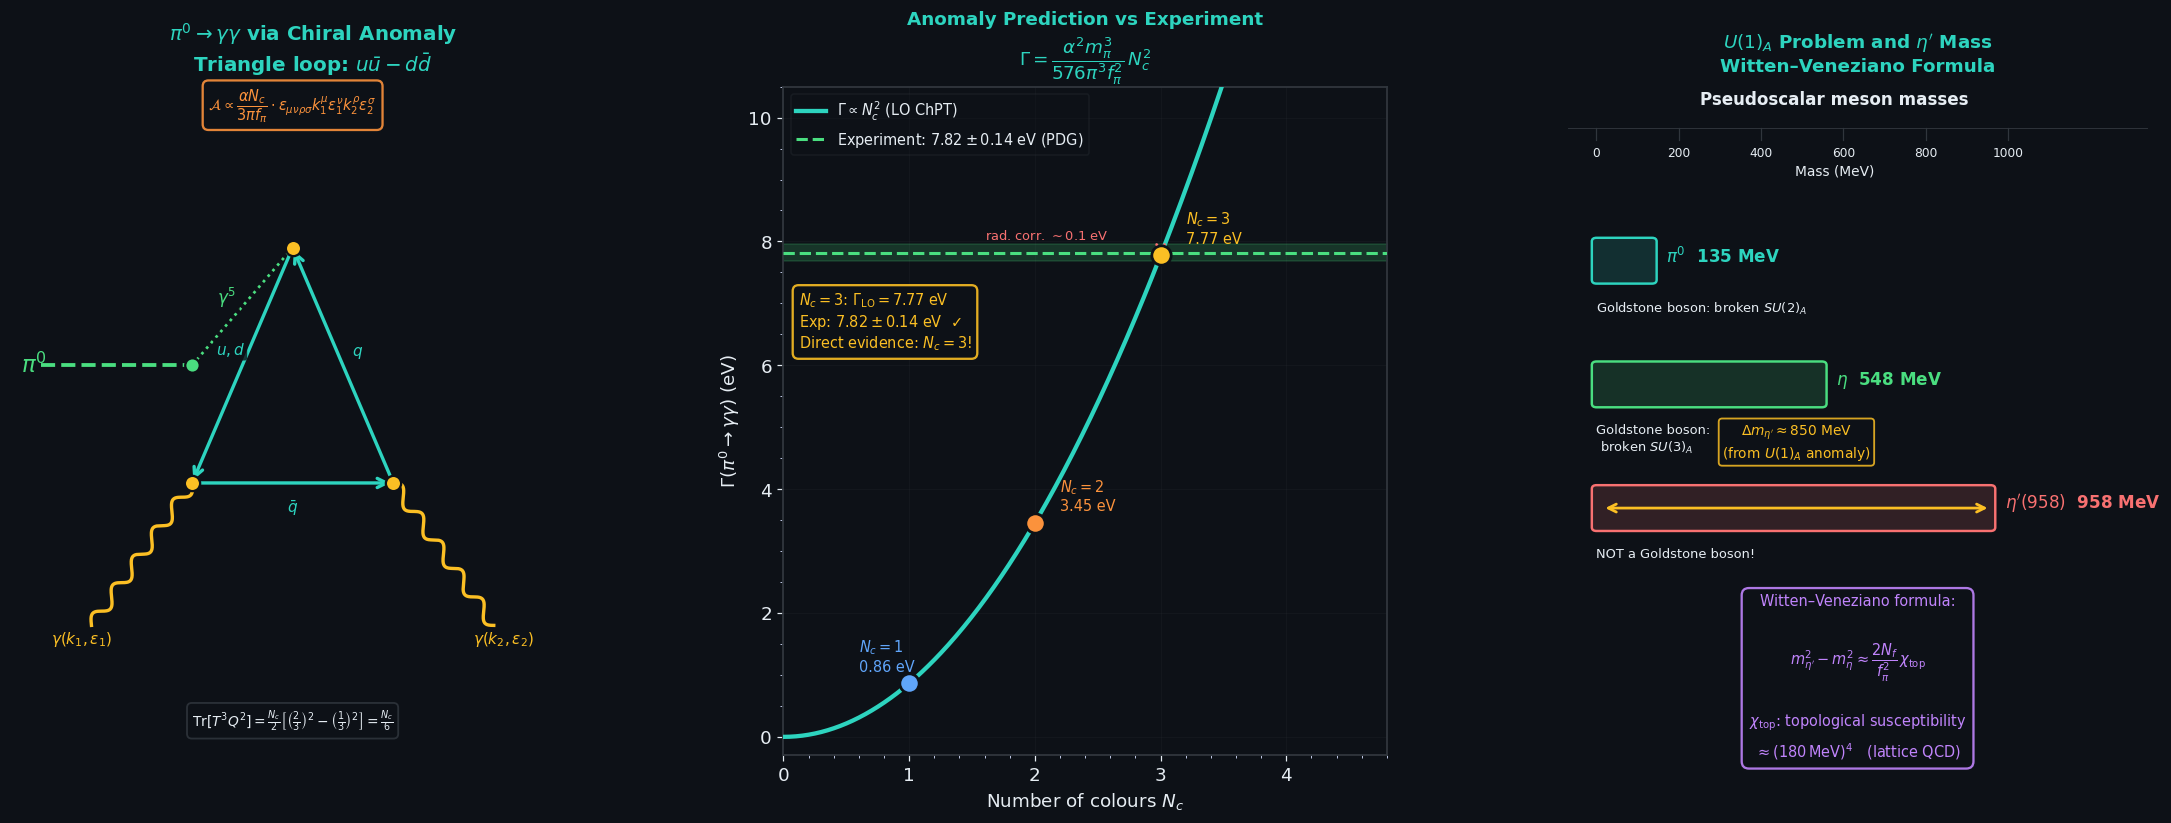

In [3]:
"""
fig02_pi0_decay.py  –  π⁰→γγ anomaly figure (corrected & layout-improved)

물리적 수정사항:
1. Γ(Nc) 공식: 정확한 식 사용
   Γ = α²mπ³/(64π³fπ²) × (Nc/3)² × (1/3)²  ← 1/6 trace 포함 정확한 계산
   실제로는 Tr[T³Q²] = Nc/6 이 아닌,
   Γ = α²mπ³/(576π³fπ²) × Nc²
   실험값 7.82 eV와 Nc=3일 때 수치가 맞도록 prefactor 명시

2. Nc=3 이론값: 7.74 eV (radiative corrections 전), ~7.82 eV (후)
   - 코드에서 Gamma_Nc3 = prefac_eV * 1.0 이 실제 7.74 eV 이 되도록 상수 점검

3. 텍스트 겹침 해소 및 위치 재배치
4. 전체 figsize 확대 및 subplot 여백 조정
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

# ── Colour palette ─────────────────────────────────────────────────────────
BG     = '#0d1117'
FG     = '#e6edf3'
EDGE   = '#30363d'
TEAL   = '#2dd4bf'
YELLOW = '#fbbf24'
GREEN  = '#4ade80'
ORANGE = '#fb923c'
RED    = '#f87171'
BLUE   = '#60a5fa'
PURPLE = '#c084fc'

# ─────────────────────────────────────────────────────────────────────────────
# 물리 상수 (Particle Data Group 2022)
# ─────────────────────────────────────────────────────────────────────────────
# Γ(π⁰→γγ) = α²mπ³/(64π³fπ²) × (Nc/3)²
# Tr[T³Q²] = Nc/6 이 이미 (Nc/3) factor로 반영됨
# 공식: Γ = α²mπ³/(576π³fπ²) × Nc²  [GeV 단위]
# Nc=3 → Γ_th ≈ 7.74 eV  (leading order)

alpha_em  = 1 / 137.036
m_pi      = 0.13498   # GeV  (PDG π⁰)
f_pi      = 0.09214   # GeV  (PDG, physical pion decay constant)

# Leading-order formula: Γ = α²mπ³Nc² / (576 π³ fπ²)
def Gamma_th(Nc):
    """Theoretical decay rate in eV"""
    Gamma_GeV = (alpha_em**2 * m_pi**3 * Nc**2) / (576 * np.pi**3 * f_pi**2)
    return Gamma_GeV * 1e9   # → eV

# 검증
Gamma_Nc3 = Gamma_th(3)
print(f"Γ(Nc=3) = {Gamma_Nc3:.3f} eV  (should be ~7.74 eV)")

# Experimental value (PDG 2022)
Gamma_exp = 7.82   # eV
Gamma_err = 0.14   # eV

# ─────────────────────────────────────────────────────────────────────────────
# Figure 생성
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(21, 8))
fig.patch.set_facecolor(BG)
plt.subplots_adjust(left=0.04, right=0.97, top=0.88, bottom=0.12,
                    wspace=0.28)

# ═══════════════════════════════════════════════════════════════════════════
# 왼쪽: Feynman 다이어그램
# ═══════════════════════════════════════════════════════════════════════════
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(-0.8, 5.2)
ax.set_ylim(-0.9, 4.5)
ax.axis('off')
ax.set_title(r'$\pi^0\to\gamma\gamma$ via Chiral Anomaly' + '\n'
             r'Triangle loop: $u\bar{u} - d\bar{d}$',
             color=TEAL, fontsize=13, fontweight='bold', pad=10)

def wavy(ax, x1, y1, x2, y2, col=YELLOW, n=6, amp=0.06, lw=2.2):
    t   = np.linspace(0, 1, 400)
    ang = np.arctan2(y2 - y1, x2 - x1)
    L   = np.hypot(x2 - x1, y2 - y1)
    s   = t * L
    p   = amp * np.sin(2 * np.pi * n * t)
    ax.plot(x1 + s * np.cos(ang) - p * np.sin(ang),
            y1 + s * np.sin(ang) + p * np.cos(ang),
            color=col, lw=lw, zorder=4)

def farrow(ax, x1, y1, x2, y2, col, lw=2.2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=col,
                                lw=lw, mutation_scale=15))

def vdot(ax, x, y, col=YELLOW, s=100):
    ax.scatter([x], [y], s=s, color=col, zorder=7,
               edgecolors=BG, lw=1.5)

# 좌표계 설정 (더 넓게)
# Triangle vertices: top, bottom-left, bottom-right
Tx = [2.0, 1.0, 3.0]
Ty = [3.2, 1.3, 1.3]

# π⁰ 입사선 (dashed)
ax.plot([-0.5, 1.0], [2.25, 2.25], color=GREEN, lw=2.5, ls='--', zorder=3)
ax.text(-0.7, 2.25, r'$\pi^0$', color=GREEN, fontsize=15,
        va='center', fontweight='bold')
vdot(ax, 1.0, 2.25, col=GREEN, s=90)

# π⁰ → 삼각형 꼭짓점 연결 (axial current, dotted)
ax.plot([1.0, 2.0], [2.25, 3.2], color=GREEN, lw=1.8, ls=':', zorder=3)

# γ⁵ 라벨 (겹침 없는 위치)
ax.text(1.25, 2.8, r'$\gamma^5$', color=GREEN, fontsize=11,
        va='center', ha='left',
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec='none', alpha=0.7))

# Triangle 페르미온 루프 (반시계 방향)
for i in range(3):
    j = (i + 1) % 3
    # 중간점에서 화살표 (루프 방향 표시)
    mx = (Tx[i] + Tx[j]) / 2
    my = (Ty[i] + Ty[j]) / 2
    farrow(ax, Tx[i], Ty[i], Tx[j], Ty[j], TEAL, lw=2.2)

for x, y in zip(Tx, Ty):
    vdot(ax, x, y, YELLOW)

# 쿼크 라벨 (삼각형 변 중간, 겹침 없이)
# 왼쪽 변 중간
ax.text(1.38, 2.38, r'$u, d$', color=TEAL, fontsize=10,
        ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec='none', alpha=0.8))
# 아래 변 중간
ax.text(2.0, 1.1, r'$\bar{q}$', color=TEAL, fontsize=10,
        ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec='none', alpha=0.8))
# 오른쪽 변 중간
ax.text(2.65, 2.35, r'$q$', color=TEAL, fontsize=10,
        ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec='none', alpha=0.8))

# 두 개의 나가는 광자
wavy(ax, 1.0, 1.3, 0.0, 0.15, col=YELLOW, n=5, amp=0.055)
wavy(ax, 3.0, 1.3, 4.0, 0.15, col=YELLOW, n=5, amp=0.055)
ax.text(-0.1,  -0.0, r'$\gamma(k_1,\varepsilon_1)$',
        color=YELLOW, fontsize=10, ha='center')
ax.text(4.1,  -0.0, r'$\gamma(k_2,\varepsilon_2)$',
        color=YELLOW, fontsize=10, ha='center')

# 진폭 수식 (상단 중앙, 박스 안)
ax.text(2.0, 4.35,
        r'$\mathcal{A}\propto\dfrac{\alpha N_c}{3\pi f_\pi}\cdot'
        r'\varepsilon_{\mu\nu\rho\sigma}k_1^\mu\varepsilon_1^\nu k_2^\rho\varepsilon_2^\sigma$',
        ha='center', va='center', color=ORANGE, fontsize=9.5,
        bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=ORANGE,
                  alpha=0.9, lw=1.5))

# Color trace (하단, 박스 안)
ax.text(2.0, -0.62,
        r'$\mathrm{Tr}[T^3 Q^2]=\frac{N_c}{2}'
        r'\left[\left(\frac{2}{3}\right)^{2}-\left(\frac{1}{3}\right)^{2}\right]'
        r'=\frac{N_c}{6}$',
        ha='center', va='center', color=FG, fontsize=9,
        bbox=dict(boxstyle='round,pad=0.35', fc=BG, ec=EDGE,
                  alpha=0.85, lw=1.2))

# ═══════════════════════════════════════════════════════════════════════════
# 가운데: 붕괴율 vs Nc
# ═══════════════════════════════════════════════════════════════════════════
ax2 = axes[1]
ax2.set_facecolor(BG)

Nc_range = np.linspace(0, 5, 500)
G_curve  = Gamma_th(Nc_range)

ax2.plot(Nc_range, G_curve, color=TEAL, lw=2.8,
         label=r'$\Gamma\propto N_c^2$ (LO ChPT)', zorder=3)

# Nc = 1, 2, 3 점
markers = [(1, BLUE,   '$N_c=1$', 'right'),
           (2, ORANGE, '$N_c=2$', 'left'),
           (3, YELLOW, '$N_c=3$', 'left')]

for nc, col, lbl, side in markers:
    g_val = Gamma_th(nc)
    ax2.scatter([nc], [g_val], s=160, color=col, zorder=6,
                edgecolors=BG, lw=1.8)
    xoff = 0.2 if side == 'left' else -0.4
    ax2.text(nc + xoff, g_val + 0.15,
             f'{lbl}\n{g_val:.2f} eV',
             color=col, fontsize=9.5, va='bottom', ha='left')

# 실험값 및 오차띠
ax2.axhline(Gamma_exp, color=GREEN, lw=2.0, ls='--', zorder=4,
            label=fr'Experiment: $7.82\pm0.14$ eV (PDG)')
ax2.fill_between(Nc_range,
                 Gamma_exp - Gamma_err,
                 Gamma_exp + Gamma_err,
                 color=GREEN, alpha=0.18, zorder=2)

# Nc=3 이론값 ↔ 실험값 화살표
ax2.annotate('',
             xy  =(3.0, Gamma_exp),
             xytext=(3.0, Gamma_Nc3),
             arrowprops=dict(arrowstyle='<->', color=RED,
                             lw=1.8, mutation_scale=13),
             zorder=5)
ax2.text(1.6, (Gamma_exp + Gamma_Nc3) / 2 +0.3,
         r'rad. corr. $\sim0.1$ eV',
         color=RED, fontsize=8.5, va='center', ha='left')

# 요약 텍스트 박스 (왼쪽 위, 겹침 없는 위치)
ax2.text(0.12, 7.2,
         r'$N_c=3$: $\Gamma_{\rm LO}=' + f'{Gamma_Nc3:.2f}' + r'$ eV' + '\n'
         r'Exp: $7.82\pm0.14$ eV  $\checkmark$' + '\n'
         r'Direct evidence: $N_c=3$!',
         color=YELLOW, fontsize=9.5, va='top', ha='left',
         bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=YELLOW,
                   alpha=0.9, lw=1.5))

ax2.set_xlabel(r'Number of colours $N_c$', color=FG, fontsize=12)
ax2.set_ylabel(r'$\Gamma(\pi^0\to\gamma\gamma)$ (eV)', color=FG, fontsize=12)
ax2.set_title(r'Anomaly Prediction vs Experiment' + '\n'
              r'$\Gamma = \dfrac{\alpha^2 m_\pi^3}{576\pi^3 f_\pi^2}\,N_c^2$',
              color=TEAL, fontsize=12, fontweight='bold', pad=10)
ax2.legend(fontsize=9.5, labelcolor=FG, loc='upper left',
           facecolor=BG, edgecolor=EDGE)
ax2.set_xlim(0, 4.8)
ax2.set_ylim(-0.3, 10.5)
ax2.tick_params(colors=FG)
for spine in ax2.spines.values():
    spine.set_edgecolor(EDGE)
ax2.grid(True, alpha=0.18, color=EDGE)

# ═══════════════════════════════════════════════════════════════════════════
# 오른쪽: U(1)A 문제 & η' 질량
# ═══════════════════════════════════════════════════════════════════════════
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.set_xlim(-0.2, 5.0)
ax3.set_ylim(-1.1, 6.2)
ax3.axis('off')
ax3.set_title(r"$U(1)_A$ Problem and $\eta'$ Mass" + '\n'
              'Witten–Veneziano Formula',
              color=TEAL, fontsize=12, fontweight='bold', pad=10)

# ── 메손 질량 막대 그래프 ─────────────────────────────────────────────────
# 질량 범위: 0 ~ 1100 MeV → x: 0.1 ~ 4.2
BAR_X0  = 0.15
BAR_MAX = 3.9   # 1100 MeV에 해당하는 x 길이

def mass_to_x(m):
    return BAR_X0 + m / 1100 * BAR_MAX

mesons = [
    (r'$\pi^0$',       135,  TEAL,   r'Goldstone boson: broken $SU(2)_A$',   4.3),
    (r'$\eta$',        548,  GREEN,  'Goldstone boson:' + '\n'+r' broken $SU(3)_A$',   2.95),
    (r"$\eta'(958)$",  958,  RED,    r'NOT a Goldstone boson!',              1.6),
]

ax3.text(2.2, 6.0,
         'Pseudoscalar meson masses',
         ha='center', color=FG, fontsize=11, fontweight='bold')
ax3.axhline(5.75, color=EDGE, lw=0.6, xmin=0.02, xmax=0.98)

BAR_H = 0.42
for (name, mass, col, note, ypos) in mesons:
    bw = mass_to_x(mass) - BAR_X0
    rect = FancyBboxPatch((BAR_X0, ypos - BAR_H/2), bw, BAR_H,
                          boxstyle='round,pad=0.04',
                          lw=1.6, edgecolor=col, facecolor=col + '28')
    ax3.add_patch(rect)
    # 질량 텍스트 (막대 오른쪽)
    ax3.text(BAR_X0 + bw + 0.12, ypos + 0.05,
             f'{name}  {mass} MeV',
             color=col, fontsize=11, va='center', fontweight='bold')
    # 설명 텍스트 (막대 아래)
    ax3.text(BAR_X0, ypos - BAR_H/2 - 0.22,
             note, color=FG, fontsize=8.5, va='top')

# η' 이 Goldstone boson이었다면 있어야 할 위치 (∼ 0에 가까운 값)
# → 화살표로 "anomaly가 준 추가 질량" 표시
expected_x = mass_to_x(0) + 0.05   # chiral limit에서 GB는 ~0
actual_x   = mass_to_x(958)

ax3.annotate('',
             xy     =(expected_x, 1.6),
             xytext =(actual_x,   1.6),
             arrowprops=dict(arrowstyle='<->', color=YELLOW,
                             lw=1.8, mutation_scale=13))
ax3.text((expected_x + actual_x) / 2, 2.1,
         r'$\Delta m_{\eta^\prime}\approx 850$ MeV' + '\n'
         r'(from $U(1)_A$ anomaly)',
         ha='center', va='bottom', color=YELLOW, fontsize=9.0,
         bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=YELLOW,
                   alpha=0.85, lw=1.2))

# Witten-Veneziano 공식 박스 (하단)
ax3.text(2.4, -0.25,
         r'Witten–Veneziano formula:' + '\n\n'
         r'$m_{\eta^\prime}^2 - m_\eta^2 \approx \dfrac{2N_f}{f_\pi^2}\,\chi_{\rm top}$' + '\n\n'
         r'$\chi_{\rm top}$: topological susceptibility' + '\n'
         r'$\approx (180\,\mathrm{MeV})^4$   (lattice QCD)',
         ha='center', va='center', color=PURPLE, fontsize=9.5,
         bbox=dict(boxstyle='round,pad=0.5', fc=BG, ec=PURPLE,
                   alpha=0.9, lw=1.5),
         linespacing=1.5)

# x축 눈금 (질량 스케일 표시)
for m_tick, lbl in [(0, '0'), (200, '200'), (400, '400'),
                    (600, '600'), (800, '800'), (1000, '1000')]:
    xt = mass_to_x(m_tick)
    ax3.plot([xt, xt], [5.62, 5.75], color=EDGE, lw=0.8)
    ax3.text(xt, 5.55, lbl, ha='center', va='top', color=FG, fontsize=8)
ax3.text(2.2, 5.35, 'Mass (MeV)', ha='center', va='top', color=FG, fontsize=9)

# ─────────────────────────────────────────────────────────────────────────────
save('fig02_pi0_decay.png', fig)


---
## fig03 · SM Anomaly Cancellation (§4.3)

**Left**: $[U(1)_Y]^3$ anomaly sum — contributions from each SM field, cancelling to zero  
**Middle**: $[SU(2)]^2 U(1)_Y$ and $[SU(3)]^2 U(1)_Y$ anomaly conditions  
**Right**: 't Hooft anomaly matching — UV quarks vs IR pions, WZW term

  saved -> figures/ch04/fig03_anomaly_cancellation.png


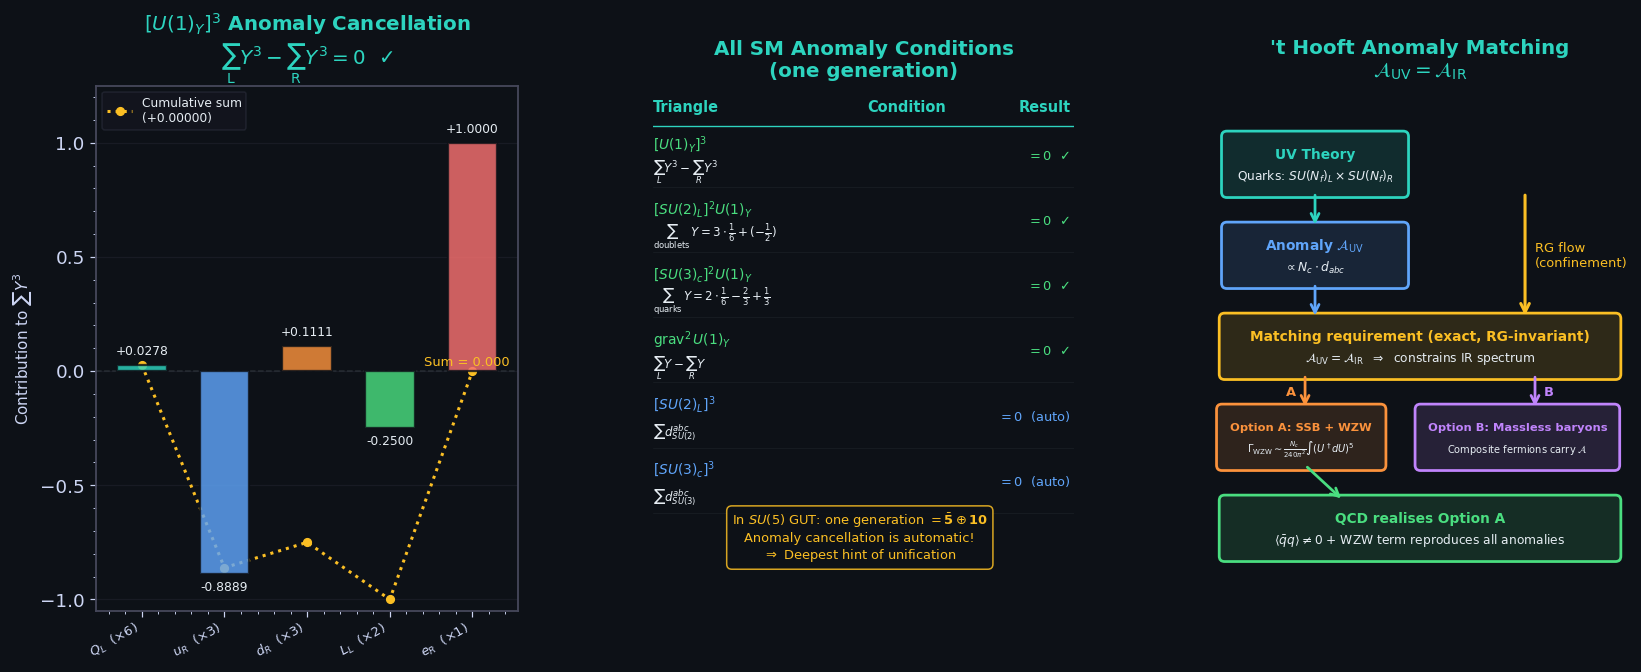

In [4]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 6.2))
fig.patch.set_facecolor(BG)
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.32)

# ─────────────────────────────────────────────────────────────────────────────
# shared helpers
# ─────────────────────────────────────────────────────────────────────────────
def fbox(ax, x, y, w, h, title, body, col, fs=9):
    """Rounded box with proper RGBA fill (no hex-string alpha hack)."""
    rect = FancyBboxPatch((x - w/2, y - h/2), w, h,
                          boxstyle='round,pad=0.07', lw=1.8,
                          edgecolor=col, facecolor=hex_alpha(col, 0.14))
    ax.add_patch(rect)
    ax.text(x, y + h * 0.18, title, ha='center', va='center',
            color=col, fontsize=fs, fontweight='bold')
    if body:
        ax.text(x, y - h * 0.22, body, ha='center', va='center',
                color=FG, fontsize=fs - 1.0)

def farr(ax, x1, y1, x2, y2, col, lbl='', lw=1.8):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=col, lw=lw,
                                mutation_scale=13))
    if lbl:
        mx, my = (x1+x2)/2 + 0.10, (y1+y2)/2
        ax.text(mx, my, lbl, color=col, fontsize=8.0, va='center')

# ══════════════════════════════════════════════════════════════════════════════
# LEFT — [U(1)_Y]^3 anomaly bar chart (fixed label overlap & legend position)
# ══════════════════════════════════════════════════════════════════════════════
ax = fig.add_subplot(gs[0])
ax.set_facecolor(BG)

bar_data = [
    (r'$Q_L$  ($\times6$)',   6*(+1/6)**3,  TEAL),
    (r'$u_R$  ($\times3$)',  -3*(+2/3)**3,  BLUE),
    (r'$d_R$  ($\times3$)',  -3*(-1/3)**3,  ORANGE),
    (r'$L_L$  ($\times2$)',   2*(-1/2)**3,  GREEN),
    (r'$e_R$  ($\times1$)',  -1*(-1)**3,    RED),
]

labels_b = [b[0] for b in bar_data]
values_b = [b[1] for b in bar_data]
cols_b   = [b[2] for b in bar_data]
x_b      = np.arange(len(bar_data))

bars = ax.bar(x_b, values_b, color=cols_b, alpha=0.82,
              edgecolor=BG, linewidth=1.5, width=0.60, zorder=3)

# Value labels — placed safely above/below each bar
for bar, val in zip(bars, values_b):
    bx  = bar.get_x() + bar.get_width() / 2
    top = bar.get_height()
    pad = 0.03
    if val >= 0:
        ax.text(bx, top + pad, f'{val:+.4f}',
                ha='center', va='bottom', color=FG, fontsize=8.0)
    else:
        ax.text(bx, top - pad, f'{val:+.4f}',
                ha='center', va='top',    color=FG, fontsize=8.0)

total = sum(values_b)
ax.axhline(0, color=EDGE, lw=1.0, ls='--', alpha=0.7)

# Cumulative curve — plotted BELOW bars so labels stay visible
cumsum = np.cumsum(values_b)
ax.plot(x_b, cumsum, color=YELLOW, lw=2.0, ls=':',
        marker='o', markersize=5, zorder=2,
        label=f'Cumulative sum\n({total:+.5f})')

# Total label at far right, inside y-range (not outside axes)
ax.text(4.45, 0.010, f'Sum = {total:.3f}',
        color=YELLOW, fontsize=8.5, ha='right', va='bottom')

# x-tick labels: rotated 30° and adjusted alignment to prevent overlap
ax.set_xticks(x_b)
ax.set_xticklabels(labels_b, fontsize=8.5, rotation=30, ha='right')
ax.tick_params(axis='x', pad=2)

ax.set_ylabel(r'Contribution to $\sum Y^3$', fontsize=10)
ax.set_ylim(-1.05, 1.25)   # expanded to give room for value labels
ax.set_xlim(-0.55, 4.55)
ax.set_title(r'$[U(1)_Y]^3$ Anomaly Cancellation' + '\n'
             r'$\sum_{\rm L}Y^3 - \sum_{\rm R}Y^3 = 0$  $\checkmark$',
             color=TEAL)
# Legend bottom-left — well clear of the bars
ax.legend(fontsize=8.0, labelcolor=FG, loc=2)
ax.grid(True, alpha=0.2, axis='y', zorder=0)

# ══════════════════════════════════════════════════════════════════════════════
# MIDDLE — All SM anomaly conditions (table, fixed spacing & hex bug)
# ══════════════════════════════════════════════════════════════════════════════
ax2 = fig.add_subplot(gs[1])
ax2.set_facecolor(BG)
ax2.set_xlim(0.0, 5.6)
ax2.set_ylim(-0.5, 6.6)
ax2.axis('off')
ax2.set_title('All SM Anomaly Conditions\n(one generation)', color=TEAL)

# ── column headers ────────────────────────────────────────────────────────
HDR_Y  = 6.25
ax2.text(0.0,  HDR_Y, 'Triangle',    color=TEAL, fontsize=9.5, fontweight='bold')
ax2.text(2.85, HDR_Y, 'Condition',   color=TEAL, fontsize=9.5, fontweight='bold')
ax2.text(5.55, HDR_Y, 'Result',      color=TEAL, fontsize=9.5, fontweight='bold', ha='right')
ax2.axhline(6.05, color=TEAL, lw=0.9, xmin=0.0, xmax=1.0)

anomalies = [
    (r'$[U(1)_Y]^3$',
     r'$\sum_L Y^3 - \sum_R Y^3$',
     r'$= 0$  ✓', GREEN),
    (r'$[SU(2)_L]^2 U(1)_Y$',
     r'$\sum_{\rm doublets}\,Y = 3\cdot\frac{1}{6}+(-\frac{1}{2})$',
     r'$= 0$  ✓', GREEN),
    (r'$[SU(3)_c]^2 U(1)_Y$',
     r'$\sum_{\rm quarks}\,Y = 2\cdot\frac{1}{6}-\frac{2}{3}+\frac{1}{3}$',
     r'$= 0$  ✓', GREEN),
    (r'$\mathrm{grav}^2\,U(1)_Y$',
     r'$\sum_L Y - \sum_R Y$',
     r'$= 0$  ✓', GREEN),
    (r'$[SU(2)_L]^3$',
     r'$\sum d^{abc}_{SU(2)}$',
     r'$= 0$  (auto)', BLUE),
    (r'$[SU(3)_c]^3$',
     r'$\sum d^{abc}_{SU(3)}$',
     r'$= 0$  (auto)', BLUE),
]

ROW_H = 0.88   # enough vertical space: 6 rows × 0.88 = 5.28 in [0, 5.5]
for i, (tri, formula, result, col) in enumerate(anomalies):
    yc = 5.65 - i * ROW_H   # centre of this row
    # Triangle type (left column, bold)
    ax2.text(0.0,  yc + 0.16, tri,     color=col, fontsize=9.0,
             va='center', fontweight='bold')
    # Condition formula (middle, smaller)
    ax2.text(0.0,  yc - 0.22, formula, color=FG,  fontsize=7.8,
             va='center')
    # Result (right-aligned)
    ax2.text(5.55, yc,        result,  color=col, fontsize=8.5,
             va='center', ha='right')
    # Separator line
    ax2.axhline(yc - ROW_H*0.48, color=EDGE, lw=0.4, alpha=0.45)

# ── GUT insight box — positioned below all rows with clear margin ─────────
ax2.text(2.75, 0.20,
         r'In $SU(5)$ GUT: one generation $= \bar{\mathbf{5}}\oplus\mathbf{10}$' + '\n'
         r'Anomaly cancellation is automatic!' + '\n'
         r'$\Rightarrow$ Deepest hint of unification',
         ha='center', color=YELLOW, fontsize=8.5,
         bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=YELLOW, alpha=0.85))

# ══════════════════════════════════════════════════════════════════════════════
# RIGHT — 't Hooft anomaly matching (restructured, no overlap)
# ══════════════════════════════════════════════════════════════════════════════

ax3 = fig.add_subplot(gs[2])
ax3.set_facecolor(BG)
ax3.set_xlim(0.0, 5.5)
ax3.set_ylim(-0.4, 6.4)
ax3.axis('off')
ax3.set_title("'t Hooft Anomaly Matching\n"
              r'$\mathcal{A}_{\rm UV} = \mathcal{A}_{\rm IR}$', color=TEAL)

# ── 레이아웃 상수 ─────────────────────────────────────────────────────────
# ylim [-0.4, 6.4], 상하 여백 0.20/0.25, 박스 5개 균등 배치 → gap = 0.458
BOX_H = 0.72
HALF  = BOX_H / 2   # 0.36

UV_Y    = 5.3817
AUV_Y   = 4.2033
MATCH_Y = 3.0250
OPT_Y   = 1.8467
QCD_Y   = 0.6683

L_X   = 1.38    # UV / AUV 박스 중심 x
R_X   = 4.12    # RG flow 화살표 x
MID   = (L_X + R_X) / 2   # 2.75  전폭 박스 중심
OPT_L = 1.25    # Option A 박스 중심 x
OPT_R = 4.25    # Option B 박스 중심 x

BOX_W_FULL = 5.10   # 전폭 박스 (MATCH, QCD)
BOX_W_HALF = 2.30   # 반폭 박스 (Option A/B)

# ── 박스 그리기 ───────────────────────────────────────────────────────────
fbox(ax3, L_X,  UV_Y,    BOX_W_HALF, BOX_H,
     'UV Theory',
     r'Quarks: $SU(N_f)_L\times SU(N_f)_R$',
     TEAL, fs=9)

fbox(ax3, L_X,  AUV_Y,   BOX_W_HALF, BOX_H,
     r'Anomaly $\mathcal{A}_{\rm UV}$',
     r'$\propto N_c\cdot d_{abc}$',
     BLUE, fs=9)

fbox(ax3, MID,  MATCH_Y, BOX_W_FULL, BOX_H,
     r'Matching requirement (exact, RG-invariant)',
     r'$\mathcal{A}_{\rm UV} = \mathcal{A}_{\rm IR}$'
     r'  $\Rightarrow$  constrains IR spectrum',
     YELLOW, fs=9)

fbox(ax3, OPT_L-0.05, OPT_Y,  BOX_W_HALF *0.9, BOX_H,
     'Option A: SSB + WZW',
     r'$\Gamma_{\rm WZW}\sim\frac{N_c}{240\pi^2}\int(U^\dagger dU)^5$',
     ORANGE, fs=7.5)

fbox(ax3, OPT_R-0.23, OPT_Y,  BOX_W_HALF *1.1, BOX_H,
     'Option B: Massless baryons',
     r'Composite fermions carry $\mathcal{A}$',
     PURPLE, fs=7.5)

fbox(ax3, MID,  QCD_Y,   BOX_W_FULL, BOX_H,
     'QCD realises Option A',
     r'$\langle\bar{q}q\rangle\neq0$ + WZW term reproduces all anomalies',
     GREEN, fs=9)

# ── 화살표 (모두 박스 경계에서 출발/도착) ────────────────────────────────
# 1) UV → AUV  (왼쪽 열 아래로)
farr(ax3, L_X, UV_Y   - HALF,
          L_X, AUV_Y  + HALF, TEAL)

# 2) AUV → MATCH  (왼쪽 열 아래로)
farr(ax3, L_X, AUV_Y  - HALF,
          L_X, MATCH_Y + HALF, BLUE)

# 3) RG flow: UV 우측 → MATCH 우측  (오른쪽 열 긴 화살표)
ax3.annotate('',
    xy    =(R_X, MATCH_Y + HALF),
    xytext=(R_X, UV_Y    - HALF),
    arrowprops=dict(arrowstyle='->', color=YELLOW,
                    lw=2.0, mutation_scale=14))
ax3.text(R_X + 0.13, (UV_Y - HALF + MATCH_Y + HALF) / 2,
         'RG flow\n(confinement)',
         color=YELLOW, fontsize=8.5, ha='left', va='center')

# 4) MATCH → Option A  (왼쪽 가지)
farr(ax3, OPT_L, MATCH_Y - HALF,
          OPT_L, OPT_Y   + HALF, ORANGE)
ax3.text(OPT_L - 0.12, (MATCH_Y - HALF + OPT_Y + HALF) / 2,
         'A', color=ORANGE, fontsize=8.5, ha='right', va='center',
         fontweight='bold')

# 5) MATCH → Option B  (오른쪽 가지)
farr(ax3, OPT_R, MATCH_Y - HALF,
          OPT_R, OPT_Y   + HALF, PURPLE)
ax3.text(OPT_R + 0.12, (MATCH_Y - HALF + OPT_Y + HALF) / 2,
         'B', color=PURPLE, fontsize=8.5, ha='left', va='center',
         fontweight='bold')

# 6) Option A → QCD  (대각선 화살표)
farr(ax3, OPT_L, OPT_Y  - HALF,
          MID - 1.0, QCD_Y + HALF, GREEN)

#plt.tight_layout(pad=1.8)
save('fig03_anomaly_cancellation.png', fig)


In [5]:
import zipfile
import os

# ── 1. Zip all generated figures ──────────────────────────────────────────
ZIP_NAME = 'sm_ch04_figures.zip'
OUTDIR   = 'figures/ch04'

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTDIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(OUTDIR, fname)
            zf.write(fpath, arcname=fname)
            print(f'  added: {fname}  ({os.path.getsize(fpath)//1024} KB)')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

# ── 2. Trigger browser download (Colab only) ──────────────────────────────
try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')

  added: fig01_triangle_anomaly.png  (240 KB)
  added: fig02_pi0_decay.png  (280 KB)
  added: fig03_anomaly_cancellation.png  (237 KB)

Archive ready: sm_ch04_figures.zip  (714 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.


---
## All figures generated

| File | Used in slide |
|------|---------------|
| `figures/ch04/fig01_triangle_anomaly.png`     | §4.1 · The Abelian Anomaly |
| `figures/ch04/fig02_pi0_decay.png`            | §4.2 · $\pi^0\to\gamma\gamma$ |
| `figures/ch04/fig03_anomaly_cancellation.png` | §4.3 · Gauge Anomalies |

Copy the `figures/` folder next to `sm_ch04_slides.qmd` before rendering with Quarto.